# Random forest: 3-year restaurant survival

Goal: predict `survived_3y` before the restaurant opens.
Features and exclusions follow the EDA notebook: columns known only after opening are dropped.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

df = pd.read_csv('archive-2/restaurant_survival.csv')

## 1. Data preparation

In [4]:
df_encoded = pd.get_dummies(df, columns=["cuisine", "location_type"], dtype=int)

print(df_encoded.shape)
df_encoded.filter(regex="^(cuisine|location_type)_").head()

(45000, 31)


,cuisine_american,cuisine_cafe,cuisine_chinese,cuisine_fast_casual,cuisine_fine_dining,cuisine_indian,cuisine_italian,cuisine_japanese,cuisine_mexican,location_type_downtown,location_type_mall_foodcourt,location_type_standalone,location_type_suburb_strip,location_type_tourist_area
0,0,0,0,0,0,1,0,0,0,0,0,0,0,1
1,0,0,0,0,0,0,1,0,0,0,0,1,0,0
2,0,0,0,0,0,0,1,0,0,1,0,0,0,0
3,0,0,0,0,0,0,0,0,1,0,0,1,0,0
4,0,0,0,0,0,1,0,0,0,0,0,0,0,1


In [5]:
drop_cols = ["restaurant_id", "avg_review_rating", "review_count",
             "years_survived", "failure_reason", "survived_3y"]

X = df_encoded.drop(columns=drop_cols)
y = df_encoded["survived_3y"]

print(X.shape)

(45000, 25)


`X` has 25 columns: 11 numeric or binary features and 14 one-hot columns for `cuisine` and `location_type`.

In [7]:
from sklearn.model_selection import train_test_split

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

print(X_train.shape, X_valid.shape, X_test.shape)

print(f"train: {len(X_train):,} rows, survival rate {y_train.mean():.1%}")
print(f"valid:  {len(X_valid):,} rows, survival rate {y_valid.mean():.1%}")
print(f"test:  {len(X_test):,} rows, survival rate {y_test.mean():.1%}")

(27000, 25) (9000, 25) (9000, 25)
train: 27,000 rows, survival rate 50.6%
valid:  9,000 rows, survival rate 50.6%
test:  9,000 rows, survival rate 50.6%


The data is split 60/20/20 into training, validation and test sets, stratified by the target.

## 2. Tuning

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

folds = StratifiedKFold(5, shuffle=True, random_state=42)

for leaf in [1, 5, 10, 25, 50, 100]:
    forest = RandomForestClassifier(n_estimators=100, min_samples_leaf=leaf,
                                    random_state=42, n_jobs=-1)
    scores = cross_val_score(forest, X_train, y_train, cv=folds, scoring="roc_auc")
    print(leaf, f"{scores.mean():.3f} ± {scores.std():.3f}")

1 0.839 ± 0.004
5 0.843 ± 0.004
10 0.844 ± 0.004
25 0.842 ± 0.003
50 0.840 ± 0.003
100 0.836 ± 0.003


The forest is not sensitive to `min_samples_leaf`: values from 5 to 25 score within the fold-to-fold variation. `min_samples_leaf=10` has the best mean AUC (0.844).

## 3. Final model and evaluation

In [13]:
forest = RandomForestClassifier(n_estimators=300, min_samples_leaf=10,
                                random_state=42, n_jobs=-1)
forest.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the tota

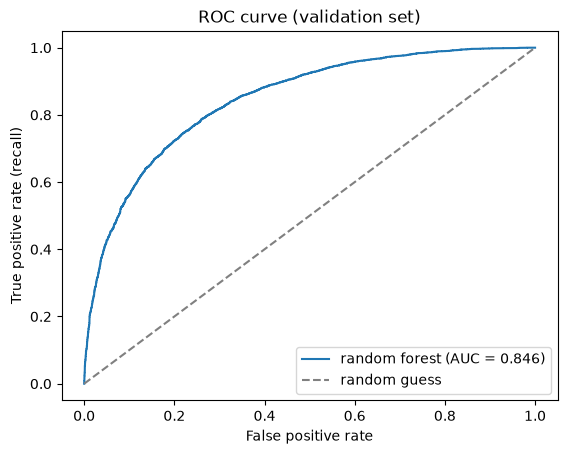

In [14]:
from sklearn.metrics import roc_curve, roc_auc_score

p = forest.predict_proba(X_valid)[:, 1]
false_alarm_rate, recall, thresholds = roc_curve(y_valid, p)
auc = roc_auc_score(y_valid, p)

plt.plot(false_alarm_rate, recall, label=f'random forest (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='random guess')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate (recall)')
plt.title('ROC curve (validation set)')
plt.legend()
plt.show()

The validation AUC (0.846) matches the cross-validation result, so the model generalises well.

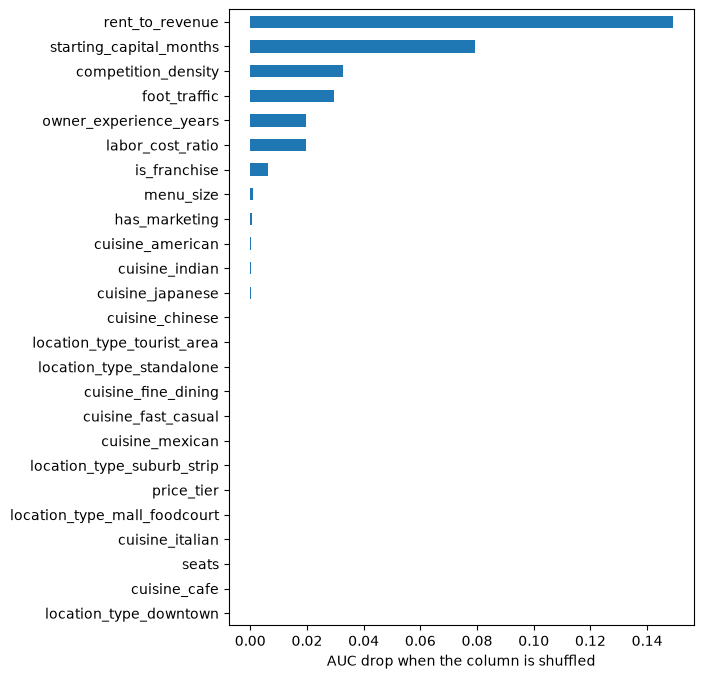

In [16]:
from sklearn.inspection import permutation_importance

r = permutation_importance(forest, X_valid, y_valid, scoring="roc_auc",
                           n_repeats=5, random_state=42)
drop = pd.Series(r.importances_mean, index=X_valid.columns)
drop.sort_values().plot.barh(figsize=(6, 8))
plt.xlabel("AUC drop when the column is shuffled"); plt.show()

`rent_to_revenue` and `starting_capital_months` matter most, followed by `competition_density` and `foot_traffic`. Location, cuisine, `seats` and `price_tier` add almost nothing, which agrees with the EDA.

In [18]:
p_test = forest.predict_proba(X_test)[:, 1]
print(f"test AUC: {roc_auc_score(y_test, p_test):.3f}")

test AUC: 0.842


The test AUC (0.842) is in line with cross-validation (0.844) and validation (0.846). The test set was used once, after all choices were made.